Imports, reproducibility and device

In [6]:
import os, random, copy, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


Locate and load the dataset

In [14]:
# ============================================
# 1. IMPORTS
# ============================================
import zipfile
from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset

# ============================================
# 2. FIND AND EXTRACT ZIP
# ============================================
zip_files = list(Path("/content").glob("*.zip"))

if not zip_files:
    raise FileNotFoundError(
        "No ZIP file found. Upload the Intel dataset ZIP to Colab."
    )

print("Available ZIP files:")
for i, file in enumerate(zip_files):
    print(f"{i}: {file.name} ({file.stat().st_size / (1024**2):.2f} MB)")

# Select the Intel dataset ZIP
zip_path = zip_files[0]

extract_dir = Path("/content/intel_dataset")
extract_dir.mkdir(exist_ok=True)

if not any(extract_dir.iterdir()):
    print("\nExtracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(extract_dir)
    print("Extraction completed!")
else:
    print("\nDataset already extracted. Skipping extraction.")

# ============================================
# 3. LOCATE TRAINING FOLDER
# ============================================
candidates = list(extract_dir.rglob("seg_train"))

train_root = next(
    (
        folder for folder in candidates
        if folder.is_dir()
        and any(item.is_dir() for item in folder.iterdir())
    ),
    None
)

if train_root is None:
    raise FileNotFoundError(
        "Could not locate seg_train inside the extracted dataset."
    )

# Handle nested seg_train/seg_train structure
if (train_root / "seg_train").is_dir():
    train_root = train_root / "seg_train"

print("\nTraining folder:", train_root)

# ============================================
# 4. VERIFY CLASS FOLDERS
# ============================================
class_folders = sorted([
    folder.name for folder in train_root.iterdir()
    if folder.is_dir()
])

print("Detected classes:", class_folders)

if len(class_folders) < 2:
    raise ValueError(
        "Only one class detected. Check the dataset folder structure."
    )

# ============================================
# 5. IMAGE TRANSFORMATIONS
# ============================================
IMAGE_SIZE = 128
BATCH_SIZE = 64

base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Data augmentation: random flip and rotation
aug_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# ============================================
# 6. LOAD DATASETS
# ============================================
full_dataset = datasets.ImageFolder(
    root=train_root,
    transform=base_transform
)

aug_dataset = datasets.ImageFolder(
    root=train_root,
    transform=aug_transform
)

NUM_CLASSES = len(full_dataset.classes)

print("\nDataset loaded successfully!")
print("Classes:", full_dataset.classes)
print("Number of classes:", NUM_CLASSES)
print("Total images:", len(full_dataset))

# ============================================
# 7. TRAIN / VALIDATION SPLIT
# ============================================
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_split, val_split = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

# Same training indices with augmentation enabled
aug_train_split = Subset(
    aug_dataset,
    train_split.indices
)

# ============================================
# 8. DATA LOADERS
# ============================================
train_loader = DataLoader(
    train_split,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_split,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

aug_train_loader = DataLoader(
    aug_train_split,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# ============================================
# 9. FINAL SUMMARY
# ============================================
print("\n========== DATASET SUMMARY ==========")
print("Training images:", train_size)
print("Validation images:", val_size)
print("Classes:", full_dataset.classes)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)
print("Device:", device)
print("=====================================")

# Check one batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Dataset setup completed successfully!")

Available ZIP files:
0: archive (1).zip (346.33 MB)

Dataset already extracted. Skipping extraction.

Training folder: /content/intel_dataset/seg_train/seg_train
Detected classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Dataset loaded successfully!
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6
Total images: 14034

========== DATASET SUMMARY ==========
Training images: 11227
Validation images: 2807
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6
Batch size: 64
Image size: 128
Device: cuda

Batch image shape: torch.Size([64, 3, 128, 128])
Batch label shape: torch.Size([64])
Dataset setup completed successfully!


In [15]:
def run_experiment(name, dropout=0.0, weight_decay=0.0,
                   early_stopping=False, augmentation=False, epochs=15):

    set_seed(SEED)

    model = CNN(dropout).to(device)
    optimizer = optim.Adam(
        model.parameters(), lr=0.001, weight_decay=weight_decay
    )
    criterion = nn.CrossEntropyLoss()

    loader = aug_train_loader if augmentation else train_loader

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    best_epoch = 0
    patience, wait = 3, 0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0, 0, 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            output = model(x)
            loss = criterion(output, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * y.size(0)
            correct += (output.argmax(1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        val_loss_sum, val_correct, val_total = 0, 0, 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                output = model(x)
                loss = criterion(output, y)

                val_loss_sum += loss.item() * y.size(0)
                val_correct += (output.argmax(1) == y).sum().item()
                val_total += y.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            wait = 0
        else:
            wait += 1

        print(
            f"{name} | Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        if early_stopping and wait >= patience:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_weights)

    result = {
        "Technique": name,
        "Train Accuracy": history["train_acc"][-1],
        "Validation Accuracy": max(history["val_acc"]),
        "Best Validation Loss": best_val_loss,
        "Best Epoch": best_epoch,
        "Epochs Run": len(history["train_loss"])
    }

    return model, history, result

print("Updated training function ready.")

Updated training function ready.


Baseline and overfitting analysis

Baseline | Epoch 1/20 | Train Loss: 1.2187 | Val Loss: 0.9959 | Val Acc: 0.6256
Baseline | Epoch 2/20 | Train Loss: 0.9741 | Val Loss: 0.9248 | Val Acc: 0.6452
Baseline | Epoch 3/20 | Train Loss: 0.8904 | Val Loss: 0.8477 | Val Acc: 0.6901
Baseline | Epoch 4/20 | Train Loss: 0.8183 | Val Loss: 0.7878 | Val Acc: 0.7182
Baseline | Epoch 5/20 | Train Loss: 0.7503 | Val Loss: 0.7393 | Val Acc: 0.7132
Baseline | Epoch 6/20 | Train Loss: 0.7132 | Val Loss: 0.6454 | Val Acc: 0.7645
Baseline | Epoch 7/20 | Train Loss: 0.6778 | Val Loss: 0.6628 | Val Acc: 0.7553
Baseline | Epoch 8/20 | Train Loss: 0.6500 | Val Loss: 0.6477 | Val Acc: 0.7624
Baseline | Epoch 9/20 | Train Loss: 0.6095 | Val Loss: 0.6060 | Val Acc: 0.7802
Baseline | Epoch 10/20 | Train Loss: 0.5772 | Val Loss: 0.5595 | Val Acc: 0.8144
Baseline | Epoch 11/20 | Train Loss: 0.5595 | Val Loss: 0.5332 | Val Acc: 0.8126
Baseline | Epoch 12/20 | Train Loss: 0.5478 | Val Loss: 0.5358 | Val Acc: 0.8115
Baseline | Epoch 13/20 | Train Loss: 

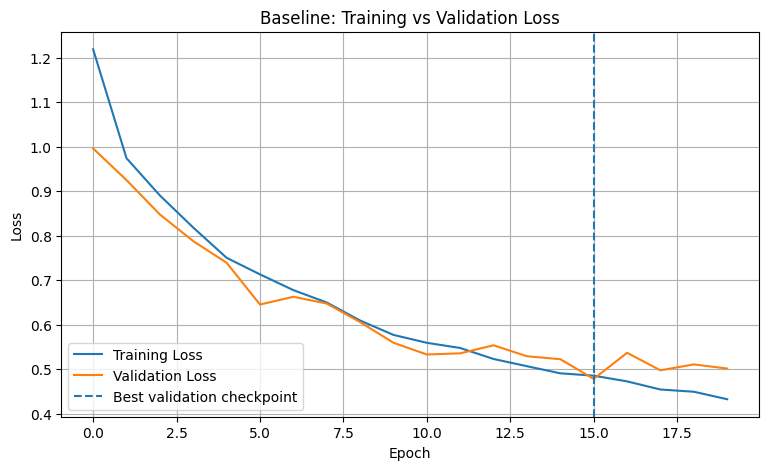


Baseline result: {'Technique': 'Baseline', 'Train Accuracy': 0.8499153825599003, 'Validation Accuracy': 0.8275739223370147, 'Best Validation Loss': 0.4783871974815964, 'Best Epoch': 16, 'Epochs Run': 20}


In [16]:
baseline_model, baseline_history, baseline_result = run_experiment(
    "Baseline", epochs=20
)

plt.figure(figsize=(9, 5))
plt.plot(baseline_history["train_loss"], label="Training Loss")
plt.plot(baseline_history["val_loss"], label="Validation Loss")

plt.axvline(
    baseline_result["Best Epoch"] - 1,
    linestyle="--",
    label="Best validation checkpoint"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

print("\nBaseline result:", baseline_result)

Four regularisation experiments

In [17]:
results = [baseline_result]
histories = {"Baseline": baseline_history}

# 1. Dropout
m_dropout, h_dropout, r_dropout = run_experiment(
    "Dropout", dropout=0.4, epochs=15
)
results.append(r_dropout)
histories["Dropout"] = h_dropout

# 2. Weight decay
m_decay, h_decay, r_decay = run_experiment(
    "Weight Decay", weight_decay=0.001, epochs=15
)
results.append(r_decay)
histories["Weight Decay"] = h_decay

# 3. Early stopping
m_early, h_early, r_early = run_experiment(
    "Early Stopping", early_stopping=True, epochs=20
)
results.append(r_early)
histories["Early Stopping"] = h_early

# 4. Data augmentation
m_aug, h_aug, r_aug = run_experiment(
    "Data Augmentation", augmentation=True, epochs=15
)
results.append(r_aug)
histories["Data Augmentation"] = h_aug

comparison = pd.DataFrame(results)
display(comparison.round(4))

Dropout | Epoch 1/15 | Train Loss: 1.2970 | Val Loss: 1.0216 | Val Acc: 0.6249
Dropout | Epoch 2/15 | Train Loss: 1.0400 | Val Loss: 0.9109 | Val Acc: 0.6619
Dropout | Epoch 3/15 | Train Loss: 0.9443 | Val Loss: 0.8268 | Val Acc: 0.6965
Dropout | Epoch 4/15 | Train Loss: 0.8890 | Val Loss: 0.7917 | Val Acc: 0.7146
Dropout | Epoch 5/15 | Train Loss: 0.8306 | Val Loss: 0.7358 | Val Acc: 0.7339
Dropout | Epoch 6/15 | Train Loss: 0.7920 | Val Loss: 0.6795 | Val Acc: 0.7649
Dropout | Epoch 7/15 | Train Loss: 0.7618 | Val Loss: 0.6679 | Val Acc: 0.7517
Dropout | Epoch 8/15 | Train Loss: 0.7327 | Val Loss: 0.6573 | Val Acc: 0.7752
Dropout | Epoch 9/15 | Train Loss: 0.7038 | Val Loss: 0.6571 | Val Acc: 0.7677
Dropout | Epoch 10/15 | Train Loss: 0.6750 | Val Loss: 0.5844 | Val Acc: 0.7941
Dropout | Epoch 11/15 | Train Loss: 0.6475 | Val Loss: 0.6263 | Val Acc: 0.7681
Dropout | Epoch 12/15 | Train Loss: 0.6394 | Val Loss: 0.5930 | Val Acc: 0.7884
Dropout | Epoch 13/15 | Train Loss: 0.6277 | Val 

,Technique,Train Accuracy,Validation Accuracy,Best Validation Loss,Best Epoch,Epochs Run
0,Baseline,0.8499,0.8276,0.4784,16,20
1,Dropout,0.7908,0.8133,0.5433,15,15
2,Weight Decay,0.8008,0.7984,0.5640,14,15
3,Early Stopping,0.8386,0.8276,0.4784,16,19
4,Data Augmentation,0.8065,0.8133,0.5271,15,15


Combine the two best techniques

In [18]:
technique_configs = {
    "Dropout": {"dropout": 0.4},
    "Weight Decay": {"weight_decay": 0.001},
    "Early Stopping": {"early_stopping": True},
    "Data Augmentation": {"augmentation": True}
}

ranked = comparison[
    comparison["Technique"] != "Baseline"
].sort_values("Validation Accuracy", ascending=False)

best_two = ranked.head(2)["Technique"].tolist()

combined_config = {}
for technique in best_two:
    combined_config.update(technique_configs[technique])

print("Two selected techniques:", best_two)
print("Combined settings:", combined_config)

combined_model, combined_history, combined_result = run_experiment(
    "Combined: " + " + ".join(best_two),
    epochs=20,
    **combined_config
)

results.append(combined_result)
histories["Combined"] = combined_history

final_comparison = pd.DataFrame(results)
display(final_comparison.round(4))

Two selected techniques: ['Early Stopping', 'Dropout']
Combined settings: {'early_stopping': True, 'dropout': 0.4}
Combined: Early Stopping + Dropout | Epoch 1/20 | Train Loss: 1.2970 | Val Loss: 1.0216 | Val Acc: 0.6249
Combined: Early Stopping + Dropout | Epoch 2/20 | Train Loss: 1.0400 | Val Loss: 0.9109 | Val Acc: 0.6619
Combined: Early Stopping + Dropout | Epoch 3/20 | Train Loss: 0.9443 | Val Loss: 0.8268 | Val Acc: 0.6965
Combined: Early Stopping + Dropout | Epoch 4/20 | Train Loss: 0.8890 | Val Loss: 0.7917 | Val Acc: 0.7146
Combined: Early Stopping + Dropout | Epoch 5/20 | Train Loss: 0.8306 | Val Loss: 0.7358 | Val Acc: 0.7339
Combined: Early Stopping + Dropout | Epoch 6/20 | Train Loss: 0.7920 | Val Loss: 0.6795 | Val Acc: 0.7649
Combined: Early Stopping + Dropout | Epoch 7/20 | Train Loss: 0.7618 | Val Loss: 0.6679 | Val Acc: 0.7517
Combined: Early Stopping + Dropout | Epoch 8/20 | Train Loss: 0.7327 | Val Loss: 0.6573 | Val Acc: 0.7752
Combined: Early Stopping + Dropout | 

,Technique,Train Accuracy,Validation Accuracy,Best Validation Loss,Best Epoch,Epochs Run
0,Baseline,0.8499,0.8276,0.4784,16,20
1,Dropout,0.7908,0.8133,0.5433,15,15
2,Weight Decay,0.8008,0.7984,0.5640,14,15
3,Early Stopping,0.8386,0.8276,0.4784,16,19
4,Data Augmentation,0.8065,0.8133,0.5271,15,15
5,Combined: Early Stopping + Dropout,0.8016,0.8251,0.5016,20,20


Reproducibility test

In [19]:
# Repeat the combined experiment with the same seed and settings
repeat_model, repeat_history, repeat_result = run_experiment(
    "Reproducibility Run",
    epochs=20,
    **combined_config
)

first_loss = combined_result["Best Validation Loss"]
second_loss = repeat_result["Best Validation Loss"]

first_acc = combined_result["Validation Accuracy"]
second_acc = repeat_result["Validation Accuracy"]

print("\nFirst run validation loss:", first_loss)
print("Second run validation loss:", second_loss)

print("\nFirst run validation accuracy:", first_acc)
print("Second run validation accuracy:", second_acc)

print("\nLoss identical:", np.isclose(first_loss, second_loss, atol=1e-6))
print("Accuracy identical:", np.isclose(first_acc, second_acc, atol=1e-6))

Reproducibility Run | Epoch 1/20 | Train Loss: 1.2970 | Val Loss: 1.0216 | Val Acc: 0.6249
Reproducibility Run | Epoch 2/20 | Train Loss: 1.0400 | Val Loss: 0.9109 | Val Acc: 0.6619
Reproducibility Run | Epoch 3/20 | Train Loss: 0.9443 | Val Loss: 0.8268 | Val Acc: 0.6965
Reproducibility Run | Epoch 4/20 | Train Loss: 0.8890 | Val Loss: 0.7917 | Val Acc: 0.7146
Reproducibility Run | Epoch 5/20 | Train Loss: 0.8306 | Val Loss: 0.7358 | Val Acc: 0.7339
Reproducibility Run | Epoch 6/20 | Train Loss: 0.7920 | Val Loss: 0.6795 | Val Acc: 0.7649
Reproducibility Run | Epoch 7/20 | Train Loss: 0.7618 | Val Loss: 0.6679 | Val Acc: 0.7517
Reproducibility Run | Epoch 8/20 | Train Loss: 0.7327 | Val Loss: 0.6573 | Val Acc: 0.7752
Reproducibility Run | Epoch 9/20 | Train Loss: 0.7038 | Val Loss: 0.6571 | Val Acc: 0.7677
Reproducibility Run | Epoch 10/20 | Train Loss: 0.6750 | Val Loss: 0.5844 | Val Acc: 0.7941
Reproducibility Run | Epoch 11/20 | Train Loss: 0.6475 | Val Loss: 0.6263 | Val Acc: 0.76

Corrected comparison table

In [20]:
settings = {
    "Baseline": "No regularisation",
    "Dropout": "Dropout = 0.4",
    "Weight Decay": "Weight decay = 0.001",
    "Early Stopping": "Patience = 3",
    "Data Augmentation": "Horizontal flip + rotation (10°)",
    "Combined": "Early stopping + Dropout (0.4)"
}

corrected_rows = []

for name, h in histories.items():
    best_idx = int(np.argmin(h["val_loss"]))

    corrected_rows.append({
        "Technique": name,
        "Setting": settings.get(name, "Combined"),
        "Training Accuracy": h["train_acc"][best_idx],
        "Validation Accuracy": h["val_acc"][best_idx],
        "Best Validation Loss": h["val_loss"][best_idx],
        "Best Epoch": best_idx + 1
    })

corrected_table = pd.DataFrame(corrected_rows)
display(corrected_table.round(4))

,Technique,Setting,Training Accuracy,Validation Accuracy,Best Validation Loss,Best Epoch
0,Baseline,No regularisation,0.8324,0.8276,0.4784,16
1,Dropout,Dropout = 0.4,0.7908,0.8133,0.5433,15
2,Weight Decay,Weight decay = 0.001,0.7952,0.7984,0.5640,14
3,Early Stopping,Patience = 3,0.8324,0.8276,0.4784,16
4,Data Augmentation,Horizontal flip + rotation (10°),0.8065,0.8133,0.5271,15
5,Combined,Early stopping + Dropout (0.4),0.8016,0.8251,0.5016,20
